# Mission 1: Hydraulic Pump Leakage - Original Random Split

**Dataset:** [UCI Condition Monitoring of Hydraulic Systems](https://archive.ics.uci.edu/dataset/447/condition+monitoring+of+hydraulic+systems)  
**Purpose:** Preserve the initial XGBoost experiment for comparison with the improved group-based split in Notebook 02.

**Important:** The random split shares operating configurations between training and testing. This is **configuration overlap**, not necessarily direct target leakage. Saved results are preserved as the historical baseline.

In [3]:
# Common imports for the original experiment
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn 
from sklearn.model_selection import train_test_split
import xgboost as xgb
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)



In [4]:
# Constants
CE = 'CE' 
CP = 'CP' 
EPS1 = 'EPS1'
FS1 = 'FS1'
FS2 = 'FS2'
PROFILE = 'profile'
PS1 = 'PS1'
PS2 = 'PS2'
PS3 = 'PS3'
PS4 = 'PS4' 
PS5 = 'PS5'
PS6 = 'PS6'
SE = 'SE'
TS1 = 'TS1'
TS2 = 'TS2'
TS3 = 'TS3'
TS4 = 'TS4'
VS1 = 'VS1'

---
# Mission 1: Machine Learning with XGBoost and SHAP

The experiment uses 2,205 recorded 60-second hydraulic cycles and predicts pump leakage severity: 0 (none), 1 (weak), or 2 (severe).

## 0. Problem understanding

Predict the **current pump leakage level** from sensor measurements within one 60-second operating cycle. This is diagnosis, not future failure prediction.

## 1. Data loading

Load the 17 sensor channels and the five condition labels from `data/`. Rows across files represent the same operating cycles.

In [5]:
# Loading data from sensor files and profile.txt

def load_data(sensor_name):
    return pd.read_csv(
        f"data/{sensor_name}.txt",
        sep=r"\s+",
        header=None,
        dtype="float32"
    ).to_numpy()

raw_sensors = {}

# cooling efficiency sensor
raw_sensors[CE] = load_data(CE)

# cooling power sensor
raw_sensors[CP] = load_data(CP)

# motor power sensor
raw_sensors[EPS1] = load_data(EPS1)

# volume flow sensors
raw_sensors[FS1] = load_data(FS1)
raw_sensors[FS2] = load_data(FS2)

# profiles of each experiment
raw_profile = pd.read_csv(
    "data/profile.txt",
    sep=r"\s+",
    header=None
)

raw_profile.columns = [
    "cooler_condition",
    "valve_condition",
    "pump_leakage",
    "accumulator_pressure",
    "stable_flag"
]

# pressure motors
raw_sensors[PS1] = load_data(PS1)
raw_sensors[PS2] = load_data(PS2)
raw_sensors[PS3] = load_data(PS3)
raw_sensors[PS4] = load_data(PS4)
raw_sensors[PS5] = load_data(PS5)
raw_sensors[PS6] = load_data(PS6)

# efficiency factor
raw_sensors[SE] = load_data(SE)

# tempreture sensors
raw_sensors[TS1] = load_data(TS1)
raw_sensors[TS2] = load_data(TS2)
raw_sensors[TS3] = load_data(TS3)
raw_sensors[TS4] = load_data(TS4)

# vibration sensor
raw_sensors[VS1] = load_data(VS1)


In [23]:
# Sample rates for each sensor, come from description.txt
sample_rates = {
    PS1: 100,
    PS2: 100,
    PS3: 100,
    PS4: 100,
    PS5: 100,
    PS6: 100,
    EPS1: 100,
    FS1: 10,
    FS2: 10,
    TS1: 1,
    TS2: 1,
    TS3: 1,
    TS4: 1,
    VS1: 1,
    CE: 1,
    CP: 1,
    SE: 1
}

units = {
    PS1: 'bar',
    PS2: 'bar',
    PS3: 'bar',
    PS4: 'bar',
    PS5: 'bar',
    PS6: 'bar',
    EPS1: 'W',
    FS1: 'l/min',
    FS2: 'l/min',
    TS1: '°C',
    TS2: '°C',
    TS3: '°C',
    TS4: '°C',
    VS1: 'mm/s',  
    CE: '%',
    CP: 'kW',
    SE: '%'
}

## 2. Exploratory Data Analysis (EDA)

Examine sensor distributions, leakage classes, stable/unstable cycles and a few time-series examples under matched operating conditions.

In [24]:
# Class balance pie chart
# mean time series with sd band
# sensors in experiment 0 (with boundries)
# leakage levels compared to stability 

# Calculate descriptive statistics for one sensor
def calculate_sensor_stats(sensor_name, data):

    data = np.asarray(data)

    # Combine measurements from all selected experiments
    values = data.flatten()

    # Quantiles
    q05, q25, q50, q75, q95 = np.quantile(
        values, [0.05, 0.25, 0.50, 0.75, 0.95]
    )

    return {
        "Sensor": sensor_name,
        "Sample Rate (Hz)": sample_rates[sensor_name],
        "Samples/Cycle": data.shape[1],
        "Cycles": data.shape[0],
        "Unit": units[sensor_name],
        "Mean": values.mean(),
        "Std": values.std(),
        "Min": values.min(),
        "Q05": q05,
        "Q25": q25,
        "Median": q50,
        "Q75": q75,
        "Q95": q95,
        "Max": values.max()
    }


# Display an EDA DataFrame with formatting and colors
def display_eda_table(df):

    stat_columns = [
        "Mean", "Std", "Min", "Q05", "Q25",
        "Median", "Q75", "Q95", "Max"
    ]

    styled = (
        df.style
        .format({col: "{:.2f}" for col in stat_columns})
        .set_table_styles([
            {
                "selector": "th.col_heading",
                "props": [
                    ("background-color", "#243b53"),
                    ("color", "white"),
                    ("font-weight", "bold"),
                    ("padding", "8px")
                ]
            },
            {
                "selector": "tbody tr:nth-child(even)",
                "props": [
                    ("background-color", "#edf2f7")
                ]
            },
            {
                "selector": "tbody tr:nth-child(even) td, tbody tr:nth-child(even) th",
                "props": [
                    ("color", "#1f2937")
                ]
            },
            {
                "selector": "td",
                "props": [
                    ("padding", "6px 10px")
                ]
            }
        ])
    )

    # Color leakage levels when the column exists
    if "Leakage" in df.columns:

        leakage_colors = {
            0: "background-color: #b7e4c7; color: #14532d; font-weight: bold",
            1: "background-color: #ffe69c; color: #854d0e; font-weight: bold",
            2: "background-color: #f5b7b1; color: #991b1b; font-weight: bold"
        }

        styled = styled.map(
            lambda value: leakage_colors.get(value, ""),
            subset=["Leakage"]
        )

    display(styled)


# Create overall EDA table
overall_stats = []

for sensor_name, data in raw_sensors.items():

    stats = calculate_sensor_stats(sensor_name, data)
    overall_stats.append(stats)

eda_overall = pd.DataFrame(overall_stats)


# Display
print("OVERALL SENSOR STATISTICS")
display_eda_table(eda_overall)


OVERALL SENSOR STATISTICS


,Sensor,Sample Rate (Hz),Samples/Cycle,Cycles,Unit,Mean,Std,Min,Q05,Q25,Median,Q75,Q95,Max
0,CE,1,60,2205,%,31.30,11.58,17.04,18.74,20.13,27.30,46.62,47.44,48.78
1,CP,1,60,2205,kW,1.81,0.28,1.02,1.47,1.55,1.74,2.14,2.19,2.91
2,EPS1,100,6000,2205,W,2495.51,218.22,2097.80,2232.00,2338.80,2425.60,2614.60,2919.60,2995.20
3,FS1,10,600,2205,l/min,6.20,3.21,0.00,0.00,7.34,7.64,7.80,8.03,20.48
4,FS2,10,600,2205,l/min,9.65,0.45,8.76,8.92,9.21,9.69,10.15,10.19,10.45
5,PS1,100,6000,2205,bar,160.49,16.13,133.13,143.09,148.91,153.94,165.56,190.96,191.92
6,PS2,100,6000,2205,bar,109.38,48.10,0.00,0.00,118.54,125.70,130.41,164.66,167.77
7,PS3,100,6000,2205,bar,1.75,0.93,0.00,0.00,1.88,2.05,2.23,2.41,18.83
8,PS4,100,6000,2205,bar,2.60,4.30,0.00,0.00,0.00,0.00,3.98,10.15,10.27
9,PS5,100,6000,2205,bar,9.16,0.58,8.32,8.40,8.55,9.11,9.85,9.96,10.04


In [8]:
# Get pump leakage labels (0, 1, 2)
leakage_labels = raw_profile["pump_leakage"].to_numpy()

leakage_stats = []

for sensor_name, data in raw_sensors.items():

    data = np.asarray(data)

    # Ensure experiments and labels are aligned
    assert len(data) == len(leakage_labels), (
        f"Row mismatch for {sensor_name}. "
        "Check that all files were loaded with header=None."
    )

    for leakage_level in [0, 1, 2]:

        # Select experiments belonging to this leakage class
        mask = leakage_labels == leakage_level
        class_data = data[mask]

        # Calculate statistics
        stats = calculate_sensor_stats(sensor_name, class_data)
        stats["Leakage"] = leakage_level

        leakage_stats.append(stats)


# Create DataFrame
eda_by_leakage = pd.DataFrame(leakage_stats)

# Place Leakage column immediately after Sensor
columns = ["Sensor", "Leakage"] + [
    col for col in eda_by_leakage.columns
    if col not in ["Sensor", "Leakage"]
]

eda_by_leakage = eda_by_leakage[columns]


# Display
print("SENSOR STATISTICS BY PUMP LEAKAGE CONDITION")
display_eda_table(eda_by_leakage)

SENSOR STATISTICS BY PUMP LEAKAGE CONDITION


,Sensor,Leakage,Sample Rate (Hz),Samples/Cycle,Cycles,Unit,Mean,Std,Min,Q05,Q25,Median,Q75,Q95,Max
0,CE,0,1,60,1221,%,31.32,11.58,17.04,18.74,20.23,27.02,46.58,47.46,48.50
1,CE,1,1,60,492,%,31.22,11.63,18.09,18.71,19.66,27.47,46.64,47.40,48.47
2,CE,2,1,60,492,%,31.33,11.52,18.08,18.81,20.25,27.39,46.70,47.42,48.78
3,CP,0,1,60,1221,kW,1.81,0.29,1.02,1.45,1.56,1.74,2.14,2.19,2.91
4,CP,1,1,60,492,kW,1.80,0.27,1.42,1.48,1.53,1.74,2.14,2.18,2.23
5,CP,2,1,60,492,kW,1.80,0.26,1.42,1.48,1.57,1.73,2.13,2.18,2.25
6,EPS1,0,100,6000,1221,W,2467.50,205.35,2162.00,2231.60,2329.60,2409.80,2520.80,2905.80,2968.40
7,EPS1,1,100,6000,492,W,2519.31,226.63,2097.80,2233.60,2345.60,2464.00,2806.60,2907.20,2987.00
8,EPS1,2,100,6000,492,W,2541.23,229.80,2124.80,2250.00,2361.80,2488.80,2833.60,2923.80,2995.20
9,FS1,0,10,600,1221,l/min,6.60,3.03,0.00,0.00,7.66,7.76,7.86,8.06,20.48


In [9]:
# Conditions we want to keep identical
control_columns = [
    "cooler_condition",
    "valve_condition",
    "accumulator_pressure"
]

# Consider stable experiments only
stable_data = raw_profile[
    raw_profile["stable_flag"] == 0
]

# Count experiments for each combination and leakage level
counts = (
    stable_data
    .groupby(control_columns + ["pump_leakage"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[0, 1, 2], fill_value=0)
)

# Find combinations containing all three leakage levels
matching_conditions = counts[
    (counts[[0, 1, 2]] > 0).all(axis=1)
]

print("Matching operating conditions found:", len(matching_conditions))

display(matching_conditions.head(10))

Matching operating conditions found: 48


pump_leakage                                            0   1   2
cooler_condition valve_condition accumulator_pressure            
3                73              90                    10  10  10
                                 100                   10  10  10
                                 115                   10  10  10
                                 130                   10  10  10
                 80              90                    10  10  10
                                 100                   10  10  10
                                 115                   10  10  10
                                 130                   10  10  10
                 90              90                    10  10  10
                                 100                   10  10  10

In [10]:
if matching_conditions.empty:

    print("No exact matching operating conditions found.")

else:

    # Prefer conditions with the most balanced number of experiments
    best_conditions = matching_conditions.min(axis=1).idxmax()

    matched_data = stable_data.copy()

    for column, value in zip(control_columns, best_conditions):
        matched_data = matched_data[
            matched_data[column] == value
        ]

    # Select one experiment for each leakage level
    selected_experiments = {}

    for level in [0, 1, 2]:

        candidates = matched_data[
            matched_data["pump_leakage"] == level
        ]

        selected_experiments[level] = int(
            candidates.sample(1, random_state=42).index[0]
        )

    print("Selected experiments:", selected_experiments)

    display(
        raw_profile.loc[list(selected_experiments.values())]
    )

Selected experiments: {0: 700, 1: 659, 2: 618}


,cooler_condition,valve_condition,pump_leakage,accumulator_pressure,stable_flag
700,3,73,0,90,0
659,3,73,1,90,0
618,3,73,2,90,0


In [11]:
# Compare the operating conditions of our selected experiments
experiment_ids = list(selected_experiments.values())

display(
    raw_profile.loc[experiment_ids, [
        "cooler_condition",
        "valve_condition",
        "pump_leakage",
        "accumulator_pressure",
        "stable_flag"
    ]]
)

,cooler_condition,valve_condition,pump_leakage,accumulator_pressure,stable_flag
700,3,73,0,90,0
659,3,73,1,90,0
618,3,73,2,90,0


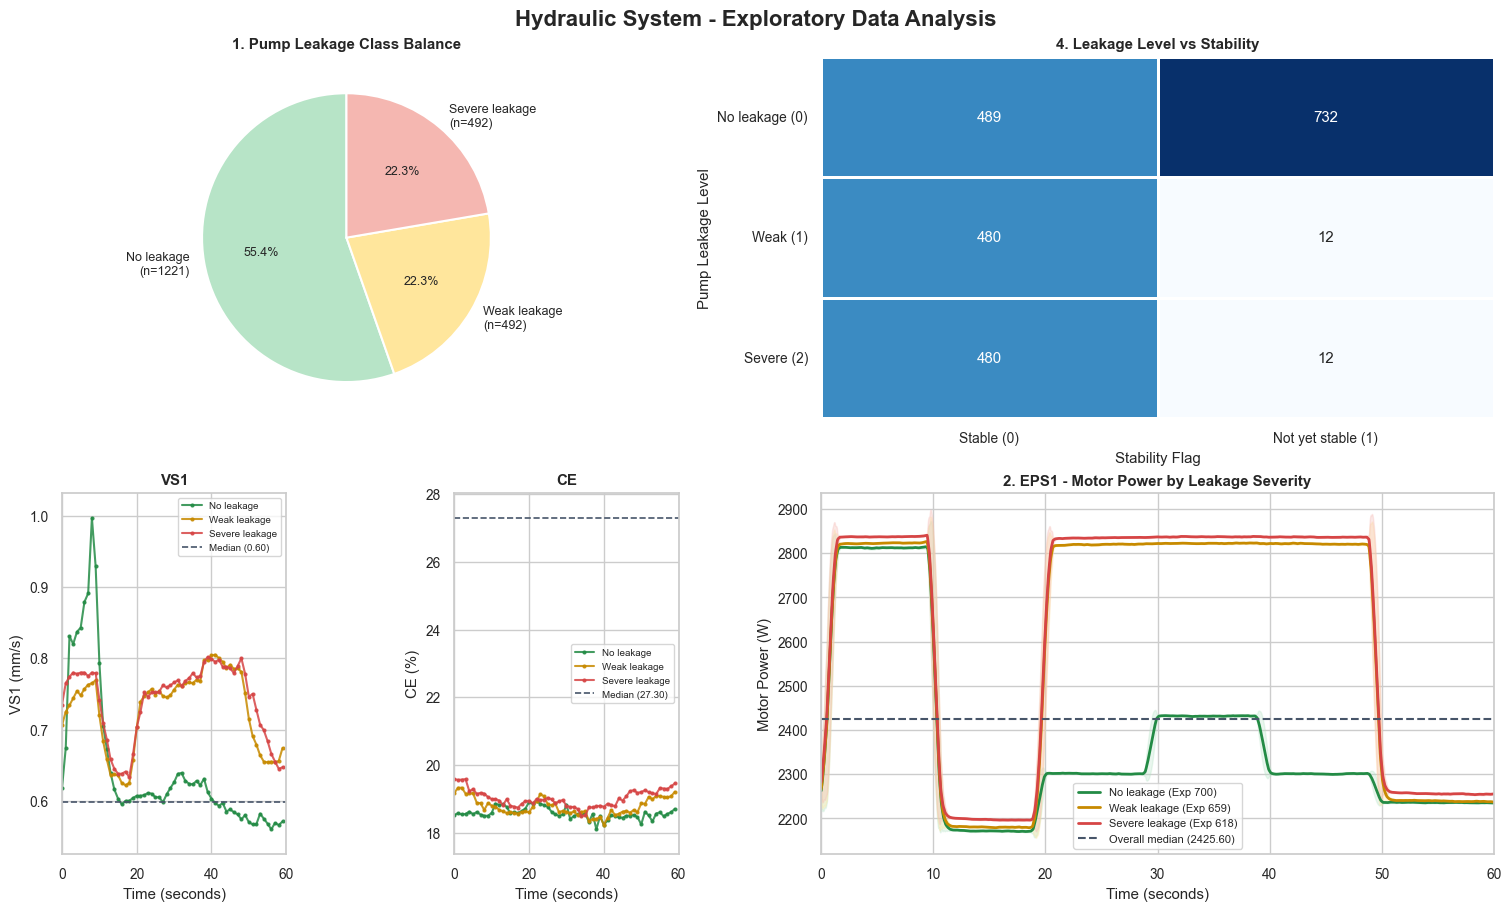

In [12]:

# ==================================================
# CONFIGURATION
# ==================================================

leakage_colors = {
    0: "#b7e4c7",
    1: "#ffe69c",
    2: "#f5b7b1"
}

line_colors = {
    0: "#238b45",
    1: "#c78a00",
    2: "#d64545"
}

leakage_names = {
    0: "No leakage",
    1: "Weak leakage",
    2: "Severe leakage"
}

# Matched experiments with identical operating conditions
selected_experiments = {
    0: 700,
    1: 659,
    2: 618
}


def sensor_median(sensor_name):
    return np.median(np.asarray(raw_sensors[sensor_name]))


# ==================================================
# FIGURE SETUP
# ==================================================

sns.set_theme(style="whitegrid", font_scale=0.9)

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 9),
    constrained_layout=True
)

fig.suptitle(
    "Hydraulic System - Exploratory Data Analysis",
    fontsize=16,
    fontweight="bold"
)


# ==================================================
# 1. LEAKAGE LEVEL BALANCE - TOP LEFT
# ==================================================

ax = axes[0, 0]

counts = (
    raw_profile["pump_leakage"]
    .value_counts()
    .reindex([0, 1, 2], fill_value=0)
)

labels = [
    f"{leakage_names[level]}\n(n={counts[level]})"
    for level in [0, 1, 2]
]

ax.pie(
    counts.values,
    labels=labels,
    colors=[leakage_colors[i] for i in [0, 1, 2]],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 1.5
    },
    textprops={"fontsize": 9}
)

ax.set_title(
    "1. Pump Leakage Class Balance",
    fontweight="bold"
)


# ==================================================
# 4. LEAKAGE VS STABILITY - TOP RIGHT
# ==================================================

ax = axes[0, 1]

stability_table = pd.crosstab(
    raw_profile["pump_leakage"].astype(int),
    raw_profile["stable_flag"].astype(int)
)

stability_table = stability_table.reindex(
    index=[0, 1, 2],
    columns=[0, 1],
    fill_value=0
)

sns.heatmap(
    stability_table,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    cbar=False,
    ax=ax
)

ax.set_title(
    "4. Leakage Level vs Stability",
    fontweight="bold"
)

ax.set_xlabel("Stability Flag")
ax.set_ylabel("Pump Leakage Level")

ax.set_xticklabels(
    ["Stable (0)", "Not yet stable (1)"],
    rotation=0
)

ax.set_yticklabels(
    ["No leakage (0)", "Weak (1)", "Severe (2)"],
    rotation=0
)


# ==================================================
# 3. VS1 AND CE - BOTTOM LEFT
# ==================================================

# Split bottom-left quadrant into two smaller plots
subplot_spec = axes[1, 0].get_subplotspec()
axes[1, 0].remove()

subgrid = subplot_spec.subgridspec(
    1, 2,
    wspace=0.15
)

sensor_axes = [
    fig.add_subplot(subgrid[0, 0]),
    fig.add_subplot(subgrid[0, 1])
]

comparison_sensors = [VS1, CE]

for ax, sensor_name in zip(
    sensor_axes,
    comparison_sensors
):

    sample_rate = sample_rates[sensor_name]
    median = sensor_median(sensor_name)

    for level, experiment_id in selected_experiments.items():

        signal = np.asarray(
            raw_sensors[sensor_name]
        )[experiment_id]

        time = np.arange(len(signal)) / sample_rate

        ax.plot(
            time,
            signal,
            color=line_colors[level],
            linewidth=1.5,
            alpha=0.85,
            marker="o",
            markersize=2,
            label=leakage_names[level]
        )

    # Overall median
    ax.axhline(
        median,
        color="#475569",
        linestyle="--",
        linewidth=1.2,
        label=f"Median ({median:.2f})"
    )

    ax.set_title(sensor_name, fontweight="bold")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel(f"{sensor_name} ({units[sensor_name]})")
    ax.set_xlim(0, 60)
    ax.margins(y=0.08)

    ax.legend(fontsize=7)


# ==================================================
# 2. EPS1 - ROLLING MEAN AND SD - BOTTOM RIGHT
# ==================================================

ax = axes[1, 1]

sensor_name = EPS1
sample_rate = sample_rates[sensor_name]

median = sensor_median(sensor_name)

for level, experiment_id in selected_experiments.items():

    signal = np.asarray(
        raw_sensors[sensor_name]
    )[experiment_id]

    time = np.arange(len(signal)) / sample_rate

    # Rolling statistics using a 1-second window
    rolling = pd.Series(signal).rolling(
        window=sample_rate,
        center=True,
        min_periods=2
    )

    rolling_mean = rolling.mean().to_numpy()
    rolling_std = rolling.std().fillna(0).to_numpy()

    ax.plot(
        time,
        rolling_mean,
        color=line_colors[level],
        linewidth=2,
        label=f"{leakage_names[level]} (Exp {experiment_id})"
    )

    ax.fill_between(
        time,
        rolling_mean - rolling_std,
        rolling_mean + rolling_std,
        color=leakage_colors[level],
        alpha=0.3
    )

# Overall median
ax.axhline(
    median,
    color="#475569",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall median ({median:.2f})"
)

ax.set_title(
    "2. EPS1 - Motor Power by Leakage Severity",
    fontweight="bold"
)

ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Motor Power (W)")
ax.set_xlim(0, 60)
ax.margins(y=0.05)
ax.legend(fontsize=8)


# ==================================================
# DISPLAY
# ==================================================

plt.show()

## 3. Data cleaning

Keep stable cycles (`stable_flag = 0`) and remove nine randomly selected stable, healthy cycles to balance the classes at 480 each. Apply the same selection to every sensor.

In [13]:
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# 1. Identify stable experiments
stable_mask = raw_profile["stable_flag"].to_numpy() == 0

# 2. Find no-leakage experiments that are stable
healthy_positions = np.flatnonzero(
    stable_mask &
    (raw_profile["pump_leakage"].to_numpy() == 0)
)

# 3. Randomly select 9 no-leakage experiments to remove
removed_positions = rng.choice(
    healthy_positions,
    size=9,
    replace=False
)

# 4. Construct final selection mask
keep_mask = stable_mask.copy()
keep_mask[removed_positions] = False

keep_positions = np.flatnonzero(keep_mask)

# 5. Clean profile
clean_profile = (
    raw_profile.iloc[keep_positions]
    .copy()
    .reset_index(drop=True)
)

# 6. Clean all sensor arrays using the SAME positions
clean_sensors = {}

for sensor_name, data in raw_sensors.items():

    data = np.asarray(data)

    assert data.shape[0] == len(raw_profile), (
        f"Row mismatch in sensor {sensor_name}"
    )

    clean_sensors[sensor_name] = data[keep_positions]

# 7. Validate results
class_counts = (
    clean_profile["pump_leakage"]
    .value_counts()
    .sort_index()
)

assert class_counts.to_dict() == {0: 480, 1: 480, 2: 480}
assert (clean_profile["stable_flag"] == 0).all()

# 8. Display cleaning summary
print("DATA CLEANING SUMMARY")
print("-" * 40)
print(f"Original experiments:       {len(raw_profile)}")
print(f"Removed unstable:          {(~stable_mask).sum()}")
print(f"Removed healthy (random):  {len(removed_positions)}")
print(f"Final experiments:         {len(clean_profile)}")

print("\nFINAL CLASS DISTRIBUTION")
print(class_counts)

print("\nRemoved healthy experiment IDs:")
print(sorted(raw_profile.index[removed_positions].tolist()))

print("\nExample cleaned sensor shapes:")
for name in list(clean_sensors)[:5]:
    print(f"{name}: {clean_sensors[name].shape}")

DATA CLEANING SUMMARY
----------------------------------------
Original experiments:       2205
Removed unstable:          756
Removed healthy (random):  9
Final experiments:         1440

FINAL CLASS DISTRIBUTION
pump_leakage
0    480
1    480
2    480
Name: count, dtype: int64

Removed healthy experiment IDs:
[427, 428, 577, 1168, 1170, 1460, 1777, 1903, 2040]

Example cleaned sensor shapes:
CE: (1440, 60)
CP: (1440, 60)
EPS1: (1440, 6000)
FS1: (1440, 600)
FS2: (1440, 600)


## 4. Feature engineering

For each of 17 sensors, calculate mean, standard deviation, minimum and maximum over a cycle. This produces 68 features per experiment.

In [14]:
features = {}

for sensor_name, data in clean_sensors.items():

    data = np.asarray(data)

    # Calculate statistics for each experiment
    features[f"{sensor_name}_mean"] = data.mean(axis=1)
    features[f"{sensor_name}_std"]  = data.std(axis=1)
    features[f"{sensor_name}_min"]  = data.min(axis=1)
    features[f"{sensor_name}_max"]  = data.max(axis=1)

# Create feature DataFrame
features_df = pd.DataFrame(features, index=clean_profile.index)

# Target labels (separate from features)
y = clean_profile["pump_leakage"].astype(int).copy()

# Validate alignment
assert len(features_df) == len(y)

# Display results
print("Feature matrix shape:", features_df.shape)
print("Target shape:", y.shape)

display(features_df.head().round(3))

Feature matrix shape: (1440, 68)
Target shape: (1440,)


,CE_mean,CE_std,CE_min,CE_max,CP_mean,CP_std,CP_min,CP_max,EPS1_mean,EPS1_std,...,TS3_min,TS3_max,TS4_mean,TS4_std,TS4_min,TS4_max,VS1_mean,VS1_std,VS1_min,VS1_max
0,19.969999,0.309,19.417999,20.681999,1.541,0.024,1.495,1.597,2676.658936,266.510010,...,55.640999,55.870998,49.563000,0.088,49.355000,49.683998,0.737,0.072,0.624,0.873
1,19.980000,0.341,19.414000,20.618000,1.543,0.026,1.495,1.591,2425.902100,216.522003,...,55.715000,55.859001,49.588001,0.078,49.405998,49.680000,0.806,0.101,0.668,1.065
2,19.664000,0.262,19.184000,20.062000,1.520,0.022,1.477,1.558,2427.283936,203.533005,...,55.640999,55.914001,49.640999,0.068,49.469002,49.737999,0.707,0.038,0.639,0.765
3,20.091000,0.297,19.337999,20.660000,1.547,0.026,1.485,1.596,2570.476074,279.643005,...,55.566002,55.882999,49.497002,0.054,49.402000,49.620998,0.735,0.032,0.676,0.819
4,19.990000,0.240,19.518999,20.552999,1.537,0.021,1.497,1.587,2568.058105,280.333008,...,55.640999,55.827999,49.511002,0.048,49.422001,49.605000,0.744,0.044,0.679,0.836


## 5. Data splitting

**Original method:** Randomly split individual cycles into training, validation and test sets. This can place the same cooler, valve and accumulator configuration in multiple sets; it tests repeated configurations rather than unseen ones.

In [15]:
RANDOM_SEED = 42

X = features_df

# First split: 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_SEED
)

# Second split: Divide temporary data equally
# 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_SEED
)

# ==================================================
# VALIDATION
# ==================================================

print("Dataset split:")
print(f"Train:      {X_train.shape}")
print(f"Validation: {X_val.shape}")
print(f"Test:       {X_test.shape}")

print("\nClass distribution:")

class_distribution = pd.DataFrame({
    "Train": y_train.value_counts().sort_index(),
    "Validation": y_val.value_counts().sort_index(),
    "Test": y_test.value_counts().sort_index()
})

display(class_distribution)

Dataset split:
Train:      (1008, 68)
Validation: (216, 68)
Test:       (216, 68)

Class distribution:


,Train,Validation,Test
pump_leakage,,,
0,336,72,72
1,336,72,72
2,336,72,72


In [16]:
test_conditions = clean_profile.loc[X_test.index, [
    "cooler_condition",
    "valve_condition",
    "accumulator_pressure"
]]

## 6. Model selection

Train a multiclass XGBoost classifier to predict leakage severity (0, 1 or 2). This notebook preserves the initial model.

In [17]:
# ==================================================
# XGBOOST - BASELINE MODEL
# ==================================================

xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=500,
    learning_rate=0.05,
    max_depth=3,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    early_stopping_rounds=30,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Train model
xgb_model.fit(
    X_train,
    y_train,
    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],
    verbose=False
)

print("Best iteration:", xgb_model.best_iteration)
print("Best validation loss:", xgb_model.best_score)

Best iteration: 497
Best validation loss: 0.03039718622177908


## 7. Model optimization

Review training and validation loss and use early stopping. No separate hyperparameter search is recorded here.

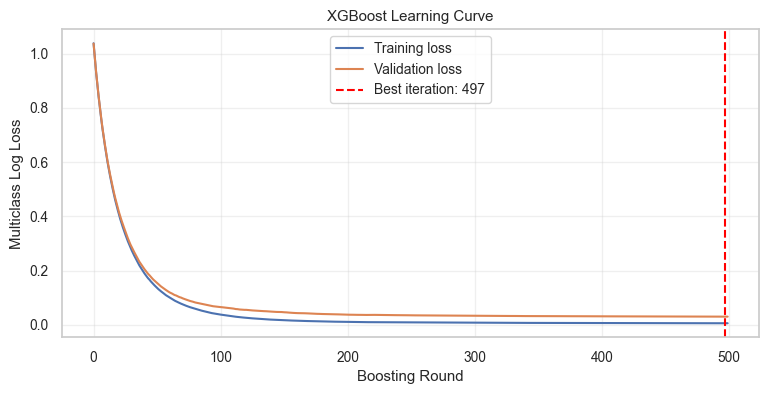

In [18]:
results = xgb_model.evals_result()

train_loss = results["validation_0"]["mlogloss"]
val_loss = results["validation_1"]["mlogloss"]

plt.figure(figsize=(9, 4))

plt.plot(train_loss, label="Training loss")
plt.plot(val_loss, label="Validation loss")

plt.axvline(
    xgb_model.best_iteration,
    color="red",
    linestyle="--",
    label=f"Best iteration: {xgb_model.best_iteration}"
)

plt.xlabel("Boosting Round")
plt.ylabel("Multiclass Log Loss")
plt.title("XGBoost Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 8. Evaluation and comparison

Evaluate test accuracy, class-specific errors and performance across operating conditions. **Interpret these results only for the original random split.**

XGBOOST - TEST RESULTS
---------------------------------------------
Accuracy: 99.54%
Macro F1: 0.9954

Classification Report:
                precision    recall  f1-score   support

    No leakage       1.00      1.00      1.00        72
  Weak leakage       1.00      0.99      0.99        72
Severe leakage       0.99      1.00      0.99        72

      accuracy                           1.00       216
     macro avg       1.00      1.00      1.00       216
  weighted avg       1.00      1.00      1.00       216



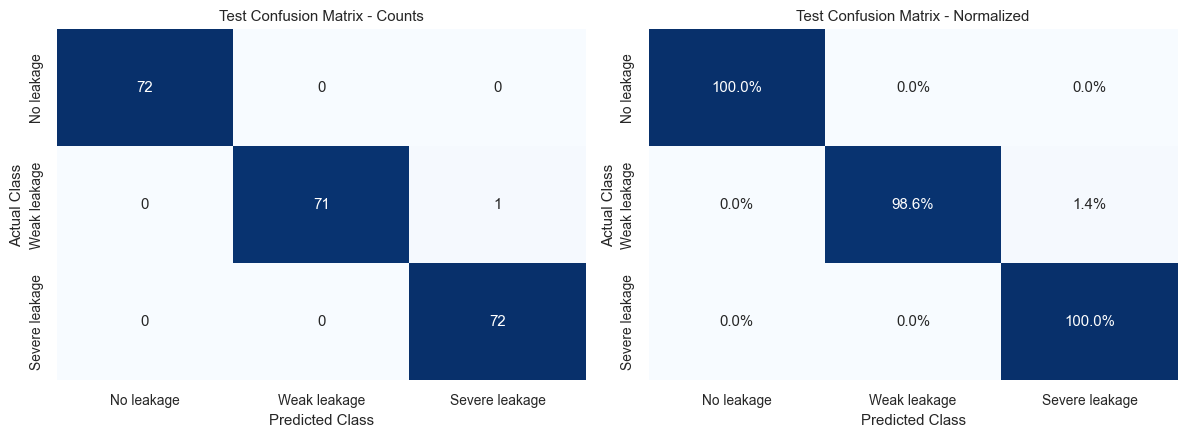

In [19]:
# ==================================================
# 1. OVERALL TEST EVALUATION
# ==================================================

class_names = ["No leakage", "Weak leakage", "Severe leakage"]
class_ids = [0, 1, 2]

# Make predictions
y_test_pred = xgb_model.predict(X_test)

# Calculate metrics
test_accuracy = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred, average="macro")

print("XGBOOST - TEST RESULTS")
print("-" * 45)
print(f"Accuracy: {test_accuracy:.2%}")
print(f"Macro F1: {test_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=class_ids,
        target_names=class_names,
        zero_division=0
    )
)

# ==================================================
# CONFUSION MATRICES
# ==================================================

cm = confusion_matrix(
    y_test, y_test_pred, labels=class_ids
)

cm_normalized = confusion_matrix(
    y_test, y_test_pred,
    labels=class_ids,
    normalize="true"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=False,
    ax=axes[0]
)

axes[0].set_title("Test Confusion Matrix - Counts")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("Actual Class")

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=False,
    ax=axes[1]
)

axes[1].set_title("Test Confusion Matrix - Normalized")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [20]:
# ==================================================
# 2. BUILD TEST RESULTS DATAFRAME
# ==================================================

# Confirm indices are aligned
assert X_test.index.equals(y_test.index)

# Retrieve operating conditions for test experiments
test_results = clean_profile.loc[
    X_test.index,
    [
        "cooler_condition",
        "valve_condition",
        "accumulator_pressure"
    ]
].copy()

test_results["Actual"] = y_test.to_numpy()
test_results["Predicted"] = y_test_pred
test_results["Correct"] = (
    test_results["Actual"] == test_results["Predicted"]
)

# ==================================================
# FUNCTION: ACCURACY BY OPERATING CONDITION
# ==================================================

def evaluate_by_condition(df, condition):

    results = []

    for value, group in df.groupby(condition):

        row = {
            "Condition": value,
            "Experiments": len(group),
            "Accuracy": group["Correct"].mean()
        }

        # Class distribution within the condition
        for level in [0, 1, 2]:
            row[f"Leakage {level} (n)"] = (
                group["Actual"] == level
            ).sum()

        results.append(row)

    return pd.DataFrame(results)


# ==================================================
# DISPLAY RESULTS
# ==================================================

conditions = [
    "cooler_condition",
    "valve_condition",
    "accumulator_pressure"
]

for condition in conditions:

    print(f"\nTEST PERFORMANCE BY {condition.upper()}")
    print("-" * 50)

    summary = evaluate_by_condition(
        test_results, condition
    )

    display(
        summary.style.format({
            "Accuracy": "{:.1%}"
        })
    )


TEST PERFORMANCE BY COOLER_CONDITION
--------------------------------------------------


,Condition,Experiments,Accuracy,Leakage 0 (n),Leakage 1 (n),Leakage 2 (n)
0,3,72,98.6%,20,28,24
1,20,59,100.0%,25,16,18
2,100,85,100.0%,27,28,30



TEST PERFORMANCE BY VALVE_CONDITION
--------------------------------------------------


,Condition,Experiments,Accuracy,Leakage 0 (n),Leakage 1 (n),Leakage 2 (n)
0,73,49,100.0%,14,15,20
1,80,56,98.2%,20,17,19
2,90,50,100.0%,17,19,14
3,100,61,100.0%,21,21,19



TEST PERFORMANCE BY ACCUMULATOR_PRESSURE
--------------------------------------------------


,Condition,Experiments,Accuracy,Leakage 0 (n),Leakage 1 (n),Leakage 2 (n)
0,90,56,100.0%,18,15,23
1,100,48,100.0%,18,16,14
2,115,52,98.1%,15,22,15
3,130,60,100.0%,21,19,20


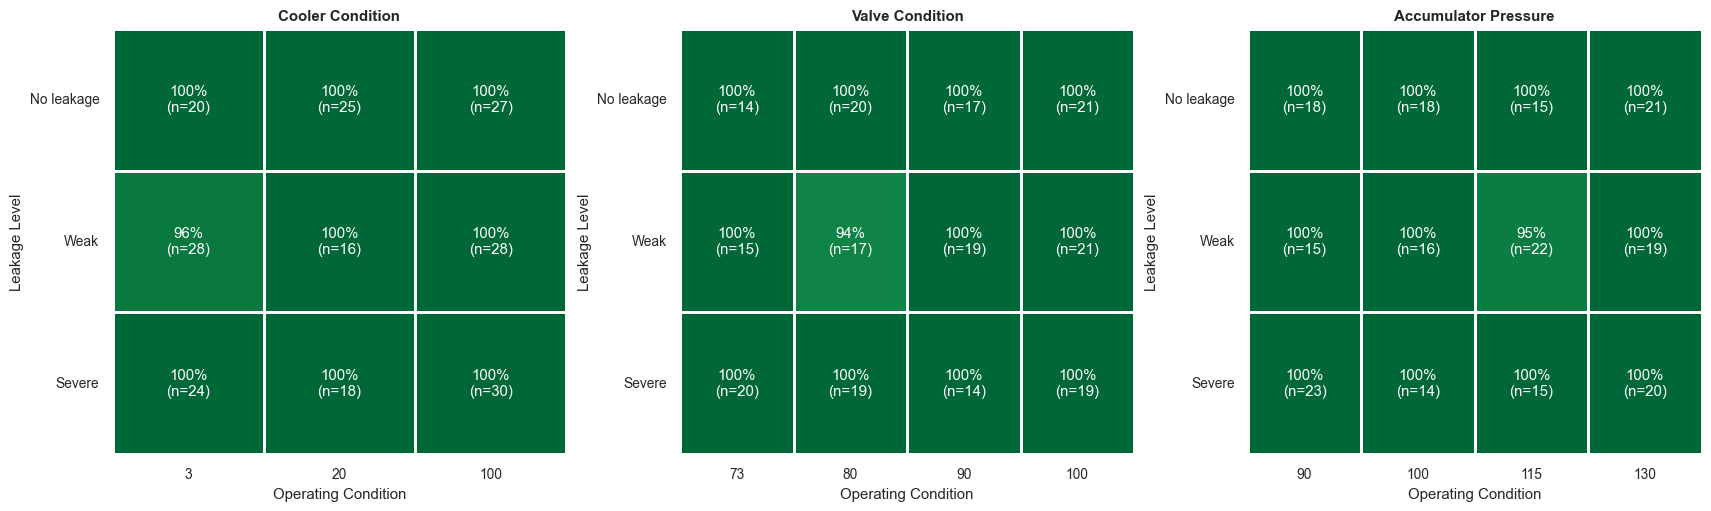

In [21]:
# ==================================================
# 3. ACCURACY BY LEAKAGE LEVEL AND OPERATING CONDITION
# ==================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True
)

conditions = [
    "cooler_condition",
    "valve_condition",
    "accumulator_pressure"
]

titles = [
    "Cooler Condition",
    "Valve Condition",
    "Accumulator Pressure"
]

for ax, condition, title in zip(axes, conditions, titles):

    # Calculate accuracy and sample count for each combination
    grouped = (
        test_results
        .groupby([condition, "Actual"])["Correct"]
        .agg(["mean", "size"])
        .reset_index()
    )

    # Accuracy matrix
    accuracy_matrix = grouped.pivot(
        index="Actual",
        columns=condition,
        values="mean"
    ) * 100

    accuracy_matrix = accuracy_matrix.reindex(
        index=[0, 1, 2]
    )

    # Count matrix
    count_matrix = grouped.pivot(
        index="Actual",
        columns=condition,
        values="size"
    ).reindex(
        index=[0, 1, 2],
        columns=accuracy_matrix.columns
    )

    # Create annotations showing accuracy and N
    annotations = accuracy_matrix.copy().astype(object)

    for i in range(accuracy_matrix.shape[0]):
        for j in range(accuracy_matrix.shape[1]):

            accuracy = accuracy_matrix.iloc[i, j]
            n = count_matrix.iloc[i, j]

            if pd.isna(accuracy):
                annotations.iloc[i, j] = ""
            else:
                annotations.iloc[i, j] = (
                    f"{accuracy:.0f}%\n(n={int(n)})"
                )

    # Plot heatmap
    sns.heatmap(
        accuracy_matrix,
        annot=annotations,
        fmt="",
        cmap="RdYlGn",
        vmin=0,
        vmax=100,
        linewidths=1,
        cbar=False,
        ax=ax
    )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Operating Condition")
    ax.set_ylabel("Leakage Level")

    ax.set_yticklabels(
        ["No leakage", "Weak", "Severe"],
        rotation=0
    )

plt.show()

In [22]:
# Operating conditions defining an experiment
condition_cols = [
    "cooler_condition",
    "valve_condition",
    "accumulator_pressure"
]

# Create an identifier for each operating configuration
groups = (
    clean_profile[condition_cols]
    .astype(str)
    .agg("_".join, axis=1)
)

# Configurations in training and testing
train_groups = set(groups.loc[X_train.index])
test_groups = groups.loc[X_test.index]

# Check whether test configurations appeared during training
seen_in_training = test_groups.isin(train_groups)

print("Unique training configurations:", len(train_groups))
print("Unique testing configurations:", test_groups.nunique())

print(
    "Test experiments with previously seen configurations:",
    f"{seen_in_training.mean():.1%}"
)

print(
    "Test experiments with unseen configurations:",
    (~seen_in_training).sum()
)

Unique training configurations: 48
Unique testing configurations: 48
Test experiments with previously seen configurations: 100.0%
Test experiments with unseen configurations: 0


## 9. Model interpretability

SHAP was not completed in this historical version. Feature importance and SHAP are developed in Notebook 02.

## 10. Summary and recommendations

The original experiment provides a useful baseline, but test configurations also occur in training. Notebook 02 uses a group-based split to test generalization to unseen **combinations** of operating conditions.

Do not describe the random-split score as evidence of performance on new configurations or new machines.

## 11. Presentation (optional)

In the final report, compare the random-split result with the group-based result and explain what each evaluation measures.